## Step 1 — Load packages

In [ ]:
%matplotlib inline                                           # عرض الرسومات تحت كل خلية مباشرة
# --- Core data-handling packages ---
import numpy as np                                           # مكتبة العمليات الرقمية
import pandas as pd                                          # مكتبة الجداول (DataFrame)

# --- Visualization packages ---
import matplotlib.pyplot as plt                              # مكتبة الرسم الأساسية
import seaborn as sns                                        # رسومات إحصائية 

# --- scikit-learn: preprocessing and pipelines ---
from sklearn.model_selection import ParameterGrid, train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV  # أدوات التقسيم والـ cross-validation والـ tuning
from sklearn.compose import ColumnTransformer  # تطبيق preprocessing مختلف على كل مجموعة أعمدة
from sklearn.pipeline import Pipeline  # ربط الـ preprocessing والنموذج بسلسلة وحدة
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # التوحيد القياسي وترميز الفئات one-hot
from sklearn.base import clone  # نسخ نموذج بدون ما نغيّر الأصلي

# --- scikit-learn: models ---
from sklearn.dummy import DummyClassifier  # النموذج الأساسي (baseline)
from sklearn.linear_model import LogisticRegression  # الانحدار اللوجستي
from sklearn.tree import DecisionTreeClassifier  # شجرة القرار
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier  # Random Forest و Gradient Boosting
from sklearn.svm import SVC  # آلة المتجهات الداعمة SVM

# --- scikit-learn: evaluation ---
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,  # مقاييس التقييم والرسومات المرتبطة فيها
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,  # باقي المقاييس المستوردة
                             RocCurveDisplay, PrecisionRecallDisplay)  # منحنى ROC
from sklearn.inspection import permutation_importance  # أهمية الأعمدة بالخلط (permutation)

# --- Settings ---
RANDOM_STATE = 42                                # رقم ثابت عشان النتائج تتكرر بكل تشغيل
NAVY, GOLD = "#1E2761", "#C9A227"           # ألوان الرسومات
sns.set_style("whitegrid")                      # خلفية بشبكة خفيفة
plt.rcParams["figure.figsize"] = (10, 5)        # الحجم الافتراضي للرسمة
pd.set_option("display.width", 100)             # عرض أوسع لطباعة الجداول
pd.set_option("display.max_columns", 30)        # عرض كل الأعمدة

print("All packages loaded successfully.")      # تأكيد إنه كل شي اتحمّل

All packages loaded successfully.


## Step 2 — Load the data

In [2]:
DATA_PATH = "german_credit_data.csv"  # مسار ملف الداتا (بنفس مجلد الـ notebook)
dataset = pd.read_csv(DATA_PATH)  # قراءة الملف إلى DataFrame

# Some CSV exports include an unnamed index column -- drop it if present.
dataset = dataset.loc[:, ~dataset.columns.str.startswith("Unnamed")]  # حذف عمود الفهرس الزايد إذا كان موجود

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")  # عدد الصفوف والأعمدة
dataset.head()  # عرض أول 5 صفوف

Dataset loaded: 1000 rows, 10 columns


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


## Step 3 — Prepare the data


In [ ]:
df = dataset.copy()                                      # نشتغل على نسخة عشان الأصل يظل سليم

# 3.1 Target: bad = 1 (positive class), good = 0
df["Risk"] = (df["Risk"] == "bad").astype(int)            # bad = 1 و good = 0

# 3.2 Missing values -> explicit "none" category
df["SavingAccounts"] = df["SavingAccounts"].fillna("none")  # القيمة الناقصة تصير فئة none
df["CheckingAccount"] = df["CheckingAccount"].fillna("none")  # القيمة الناقصة تصير فئة none

# 3.3 Feature engineering
# MonthlyPayment: how heavy is the monthly burden of this loan?
df["MonthlyPayment"] = df["CreditAmount"] / df["Duration"]     # القسط الشهري التقريبي = المبلغ ÷ المدة
# LogCreditAmount: CreditAmount is right-skewed, the log makes it more symmetric
df["LogCreditAmount"] = np.log(df["CreditAmount"])             # لوغاريتم المبلغ لتخفيف الانحراف لليمين

print("Remaining missing values:", int(df.isna().sum().sum()))  # نتأكد إنه ما ضل قيم ناقصة
print()
print("Class balance (1 = bad):")                               # عنوان توزيع الفئتين
print(df["Risk"].value_counts().rename({0: "good (0)", 1: "bad (1)"}))  # عدد good وعدد bad
df[["CreditAmount", "Duration", "MonthlyPayment", "LogCreditAmount", "Risk"]].head()  # عرض الأعمدة الجديدة جنب الهدف

Remaining missing values: 0

Class balance (1 = bad):
Risk
good (0)    700
bad (1)     300
Name: count, dtype: int64


,CreditAmount,Duration,MonthlyPayment,LogCreditAmount,Risk
0,1169,6,194.833333,7.063904,0
1,5951,48,123.979167,8.691315,1
2,2096,12,174.666667,7.647786,0
3,7882,42,187.666667,8.972337,0
4,4870,24,202.916667,8.490849,1


      CreditAmount  Duration  MonthlyPayment
Risk                                        
good        2985.5      19.2           165.8
bad         3938.1      24.9           172.0


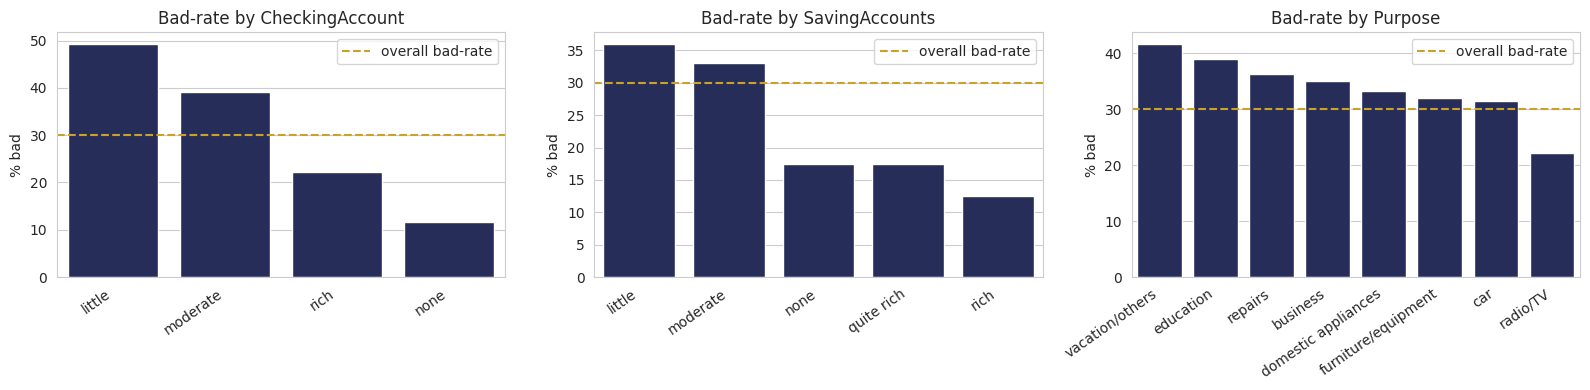

In [4]:
# Do the new features relate to Risk? Compare their average value for good vs bad applicants.
print(df.groupby("Risk")[["CreditAmount", "Duration", "MonthlyPayment"]].mean().round(1).rename(index={0: "good", 1: "bad"}))  # متوسط المبلغ والمدة والقسط لكل فئة

# Bad-rate (share of bad applicants) per category -- a very direct, model-free look at the signal
fig, axes = plt.subplots(1, 3, figsize=(16, 4))  # ثلاث رسمات جنب بعض
for ax, col in zip(axes, ["CheckingAccount", "SavingAccounts", "Purpose"]):  # رسمة لكل عمود فئوي
    rate = df.groupby(col)["Risk"].mean().sort_values(ascending=False) * 100  # نسبة bad المئوية بكل فئة، مرتبة تنازلياً
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color=NAVY)  # أعمدة نسبة bad
    ax.axhline(df["Risk"].mean() * 100, color=GOLD, linestyle="--", label="overall bad-rate")  # خط النسبة العامة للمقارنة
    ax.set_title(f"Bad-rate by {col}")  # عنوان الرسمة
    ax.set_ylabel("% bad")  # تسمية المحور العمودي
    ax.set_xlabel("")  # بدون تسمية للمحور الأفقي
    ax.set_xticks(range(len(rate)))  # تثبيت مواقع التسميات
    ax.set_xticklabels(rate.index, rotation=35, ha="right")  # تسميات مائلة عشان ما تتداخل
    ax.legend()  # إظهار مفتاح الرسمة
plt.tight_layout()  # ترتيب المسافات
plt.show()  # عرض الرسمة

<div dir="rtl" style="text-align:right">

**ملاحظات على الرسم**

- `CheckingAccount` أوضح إشارة: اللي رصيد حسابه الجاري *little* بيكونوا bad تقريباً بنص الحالات، مقابل حوالي 1 من كل 10 عند اللي **ما عندهم** حساب جاري.
- فئة `"none"` عندها **أقل** نسبة bad. هاد عكس التوقع، بس هو نمط معروف بهاي الداتا: القيمة الناقصة غالباً مش معناها "ما في حساب" حرفياً، ممكن تعني ما في معلومات عن الحساب لمتقدمين انفحصوا بطريقة مختلفة. لهيك خلّينا `"none"` فئة مستقلة وما حذفنا الصفوف ولا عبّيناها بقيمة عادية.
- `SavingAccounts` بنفس الاتجاه: مدخرات قليلة تعني نسبة bad أعلى.
- `Purpose` تأثيره أقل، الفروقات أصغر وبعض الفئات عددها قليل.

</div>

In [ ]:
# 3.4 Train / test split
# stratify=y keeps the 70/30 good/bad ratio identical in both parts.
X = df.drop(columns=["Risk"])             # X = الميزات (كل الأعمدة ما عدا الهدف)
y = df["Risk"]                            # y = الهدف

X_train, X_test, y_train, y_test = train_test_split(  # تقسيم الداتا لتدريب واختبار
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE  # 20% للاختبار، و stratify بيحافظ على نسبة 70/30 بالجزأين
)

print(f"Train: {X_train.shape[0]} rows  |  bad-rate = {y_train.mean():.1%}")  # حجم التدريب ونسبة bad فيه
print(f"Test : {X_test.shape[0]} rows  |  bad-rate = {y_test.mean():.1%}")  # حجم الاختبار ونسبة bad فيه

Train: 800 rows  |  bad-rate = 30.0%
Test : 200 rows  |  bad-rate = 30.0%


## Step 4 — Build a preprocessing pipeline



In [ ]:
numeric_features = ["Age", "Job", "CreditAmount", "Duration", "MonthlyPayment", "LogCreditAmount"]    # الأعمدة الرقمية (بتتوحّد)
categorical_features = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose"]             # الأعمدة الفئوية (بتتحول one-hot)

preprocessor = ColumnTransformer([                                                                    # preprocessing مختلف لكل مجموعة أعمدة
    ("num", StandardScaler(), numeric_features),                                                      # توحيد قياسي: متوسط 0 وانحراف 1
    # handle_unknown="ignore": if a category appears only in new data, encode it as all zeros
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),                            # one-hot: عمود 0/1 لكل فئة
])

# Quick look: how many columns does the model actually receive after encoding?
preprocessor.fit(X_train)                                  # التعلّم من بيانات التدريب بس
n_features = preprocessor.transform(X_train).shape[1]     # عدد أعمدة المدخلات بعد الترميز
print(f"{X_train.shape[1]} raw columns  ->  {n_features} model input columns after one-hot encoding")  # مقارنة العدد قبل وبعد الترميز

11 raw columns  ->  28 model input columns after one-hot encoding


## Step 5 — Baseline model



In [7]:
baseline = Pipeline([("prep", preprocessor), ("model", DummyClassifier(strategy="most_frequent"))])  # preprocessing + نموذج بيتوقع الفئة الأكثر شيوعاً دايماً
baseline.fit(X_train, y_train)  # التدريب
pred = baseline.predict(X_test)  # التوقعات على الـ test

print(f"Baseline accuracy : {accuracy_score(y_test, pred):.3f}")  # الدقة
print(f"Baseline recall   : {recall_score(y_test, pred):.3f}   (share of bad applicants caught)")  # نسبة العملاء السيئين اللي انمسكوا
print(f"Baseline ROC-AUC  : {roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]):.3f}")  # قدرة الترتيب (0.5 = عشوائي)

Baseline accuracy : 0.700
Baseline recall   : 0.000   (share of bad applicants caught)
Baseline ROC-AUC  : 0.500


<div dir="rtl" style="text-align:right">

**ملاحظات**

- دقة 70% مع **recall = 0%** هي الدرس الأساسي: النموذج ممكن يبين كويس بالـ accuracy وهو ما بيمسك ولا عميل سيء. لهيك بنتابع كمان الـ recall والـ precision والـ ROC-AUC.
- ROC-AUC = 0.5 معناها "مش أحسن من ترتيب عشوائي". أي نموذج حقيقي لازم يتخطاها.

</div>

## Step 6 — Compare several models with cross-validation



In [8]:
models = {  # النماذج اللي بدنا نقارنها
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),  # نموذج خطي، balanced = وزن أكبر لفئة bad
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),  # شجرة بعمق محدود لتقليل الـ overfitting
    "Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),  # 300 شجرة والقرار بالتصويت
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),  # أشجار صغيرة كل وحدة بتصلّح أخطاء اللي قبلها
    "SVM (RBF)":           SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE),  # probability=True عشان نحصل على احتمالات
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)  # 5 طيّات مع الحفاظ على نسبة الفئات
scoring = ["roc_auc", "recall", "precision", "f1", "accuracy"]  # المقاييس اللي بدنا نحسبها

rows = {}  # لتخزين نتيجة كل نموذج
for name, model in models.items():  # نمر على كل نموذج
    pipe = Pipeline([("prep", preprocessor), ("model", model)])  # الـ preprocessing جزء من النموذج، فما في leakage داخل الـ folds
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)  # تدريب وتقييم على الـ 5 طيّات
    rows[name] = {m: scores[f"test_{m}"].mean() for m in scoring}  # متوسط كل مقياس عبر الطيّات
    rows[name]["roc_auc_std"] = scores["test_roc_auc"].std()  # الانحراف المعياري للـ AUC (مدى الثبات)

results = pd.DataFrame(rows).T.sort_values("roc_auc", ascending=False).round(3)  # جدول النتائج مرتب حسب ROC-AUC
results  # عرض الجدول

,roc_auc,recall,precision,f1,accuracy,roc_auc_std
SVM (RBF),0.771,0.708,0.507,0.590,0.706,0.038
Logistic Regression,0.749,0.717,0.488,0.580,0.689,0.057
Random Forest,0.743,0.367,0.591,0.452,0.734,0.054
Gradient Boosting,0.740,0.392,0.580,0.464,0.735,0.045
Decision Tree,0.682,0.612,0.431,0.504,0.645,0.068


## Step 7 — Tune the best model



In [ ]:
param_grids = {                                                   # الإعدادات اللي بدنا نجربها لكل نموذج
    "Logistic Regression": {"model__C": np.logspace(-3, 2, 20)},  # C = قوة الـ regularization (أصغر = أقوى)
    "Random Forest": {                                            # 300 شجرة والقرار بالتصويت
        "model__n_estimators": [200, 300, 500],                  # عدد الأشجار
        "model__max_depth": [3, 5, 8, 12, None],                 # أقصى عمق للشجرة
        "model__min_samples_leaf": [1, 3, 5, 10],                # أقل عدد عينات بالورقة
        "model__max_features": ["sqrt", 0.3, 0.5],                # عدد الأعمدة المجرّبة عند كل تقسيم
    },
    "Gradient Boosting": {                                        # أشجار صغيرة كل وحدة بتصلّح أخطاء اللي قبلها
        "model__n_estimators": [50, 100, 200, 300],                # عدد الأشجار
        "model__learning_rate": [0.01, 0.03, 0.05, 0.1],            # سرعة التعلم
        "model__max_depth": [2, 3, 4],                           # أقصى عمق للشجرة
        "model__subsample": [0.6, 0.8, 1.0],                     # نسبة العينات المستخدمة لكل شجرة
        "model__min_samples_leaf": [1, 5, 10],                    # أقل عدد عينات بالورقة
    },
    "SVM (RBF)": {"model__C": np.logspace(-2, 2, 10), "model__gamma": ["scale", 0.01, 0.03, 0.1]},  # C و gamma بيتحكموا بمرونة حدود القرار
    "Decision Tree": {"model__max_depth": [2, 3, 4, 5, 7], "model__min_samples_leaf": [5, 10, 20, 40]},  # شجرة بعمق محدود لتقليل الـ overfitting
}

top2 = results.index[:2].tolist()  # أفضل نموذجين من المقارنة
print("Tuning the top-2 models:", top2, "\n")  # طباعة أسماء النموذجين

tuned = {}  # لتخزين نتائج البحث
for name in top2:  # نمر على كل نموذج من الاثنين
    pipe = Pipeline([("prep", preprocessor), ("model", clone(models[name]))])  # نسخة جديدة من النموذج داخل بايبلاين
    search = RandomizedSearchCV(pipe, param_grids[name], n_iter=min(25, len(ParameterGrid(param_grids[name]))), scoring="roc_auc",  # بحث عشوائي بـ cross-validation والمقياس ROC-AUC
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1)  # عدد التجارب لا يزيد عن عدد التركيبات الممكنة
    search.fit(X_train, y_train)  # التجربة على بيانات التدريب بس
    tuned[name] = search  # حفظ نتيجة البحث
    before = results.loc[name, "roc_auc"]  # النتيجة قبل الـ tuning
    print(f"{name:20s} CV ROC-AUC: {before:.3f} -> {search.best_score_:.3f}")  # قبل وبعد الـ tuning
    print(f"{'':20s} best params: { {k.replace('model__', ''): v for k, v in search.best_params_.items()} }")  # أفضل إعدادات انلقت

best_name = max(tuned, key=lambda n: tuned[n].best_score_)  # النموذج صاحب أعلى CV score
best_model = tuned[best_name].best_estimator_  # أفضل نسخة مدرّبة جاهزة للتوقع
print(f"\nSelected final model: {best_name}")  # اسم النموذج النهائي

Tuning the top-2 models: ['SVM (RBF)', 'Logistic Regression'] 



SVM (RBF)            CV ROC-AUC: 0.771 -> 0.777
                     best params: {'gamma': 0.1, 'C': np.float64(0.5994842503189409)}


Logistic Regression  CV ROC-AUC: 0.749 -> 0.753
                     best params: {'C': np.float64(0.12742749857031335)}

Selected final model: SVM (RBF)


<div dir="rtl" style="text-align:right">

**ملاحظات**

- الـ tuning أعطى تحسن بسيط بس (الـ CV ROC-AUC زاد حوالي 0.004 إلى 0.006). هاد طبيعي: الإعدادات الافتراضية كانت معقولة أصلاً والداتا صغيرة وفيها ضوضاء.
- اختيار النموذج النهائي حسب الـ cross-validation على بيانات التدريب (مش على الـ test) مهم جداً. لو اخترنا حسب أحسن نتيجة على الـ test بنسرّب معلومات الـ test لاختيار النموذج.

</div>

## Step 8 — Final evaluation on the test set

This is the first (and only) time the test set is used for evaluation. The numbers here are our
best estimate of how the model would behave on **new applicants**.

In [11]:
proba_test = best_model.predict_proba(X_test)[:, 1]  # احتمال إنه المتقدم bad
pred_test = (proba_test >= 0.5).astype(int)  # القرار: bad إذا الاحتمال ≥ 0.5

print(f"Final model: {best_name}\n")  # اسم النموذج
print(f"ROC-AUC  : {roc_auc_score(y_test, proba_test):.3f}")  # قدرة الترتيب
print(f"Accuracy : {accuracy_score(y_test, pred_test):.3f}")  # نسبة التوقعات الصحيحة
print(f"Recall   : {recall_score(y_test, pred_test):.3f}")  # من كل السيئين، كم مسكنا؟
print(f"Precision: {precision_score(y_test, pred_test):.3f}")  # من اللي علّمناهم سيئين، كم فعلاً سيء؟
print(f"F1       : {f1_score(y_test, pred_test):.3f}\n")  # توازن بين precision و recall
print(classification_report(y_test, pred_test, target_names=["good", "bad"]))  # تقرير مفصل لكل فئة

Final model: SVM (RBF)

ROC-AUC  : 0.775
Accuracy : 0.760
Recall   : 0.450
Precision: 0.643
F1       : 0.529

              precision    recall  f1-score   support

        good       0.79      0.89      0.84       140
         bad       0.64      0.45      0.53        60

    accuracy                           0.76       200
   macro avg       0.72      0.67      0.68       200
weighted avg       0.75      0.76      0.75       200



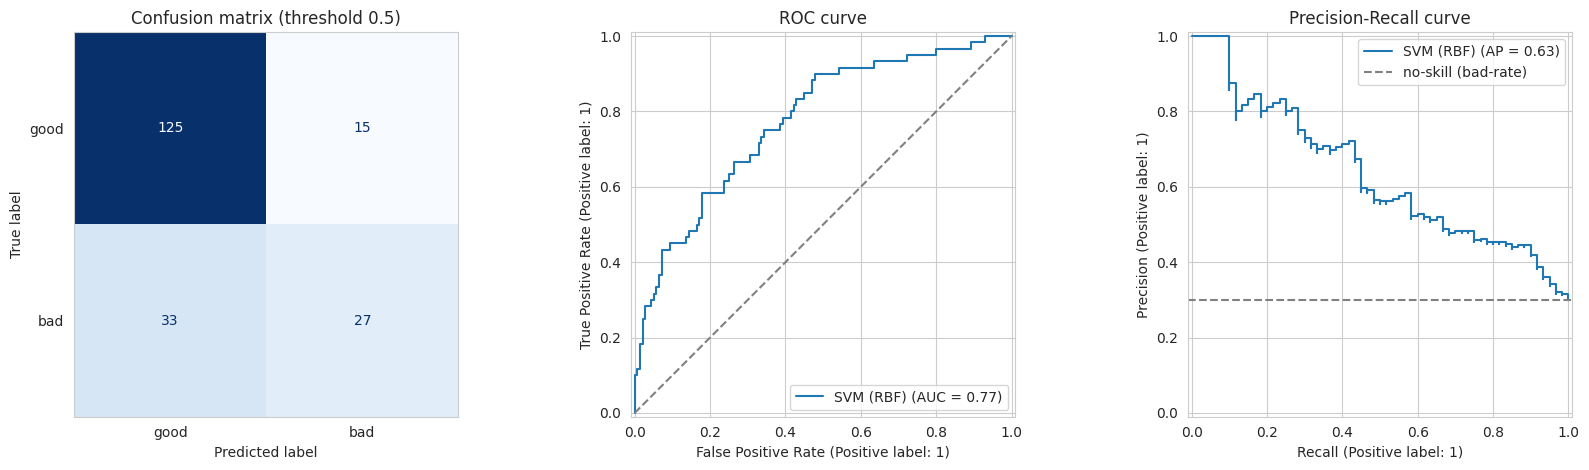

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))  # ثلاث رسمات جنب بعض

# (a) Confusion matrix: rows = truth, columns = prediction
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["good", "bad"],  # مصفوفة الالتباس: الصفوف = الحقيقة، الأعمدة = التوقع
                                        cmap="Blues", colorbar=False, ax=axes[0])  # ألوان المصفوفة بدون شريط ألوان
axes[0].set_title("Confusion matrix (threshold 0.5)")  # عنوان الرسمة
axes[0].grid(False)  # إلغاء الشبكة عن المصفوفة

# (b) ROC curve: trade-off between catching bad applicants and wrongly flagging good ones
RocCurveDisplay.from_predictions(y_test, proba_test, ax=axes[1], name=best_name)  # منحنى ROC
axes[1].plot([0, 1], [0, 1], "--", color="grey")  # الخط القطري = تخمين عشوائي
axes[1].set_title("ROC curve")  # عنوان الرسمة

# (c) Precision-Recall curve: more informative when the positive class is the minority
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=axes[2], name=best_name)  # منحنى Precision-Recall
axes[2].axhline(y_test.mean(), linestyle="--", color="grey", label="no-skill (bad-rate)")  # خط نسبة bad الأصلية = الحد الأدنى للمقارنة
axes[2].legend()  # مفتاح الرسمة
axes[2].set_title("Precision-Recall curve")  # عنوان الرسمة

plt.tight_layout()  # ترتيب المسافات
plt.show()  # عرض الرسمة

<div dir="rtl" style="text-align:right">

**ملاحظات**

- الـ ROC-AUC على الـ test (0.775) قريب جداً من قيمة الـ cross-validation (0.777)، وهاي إشارة منيحة: **ما في overfitting** على بيانات التدريب، وما كنا محظوظين بالتقسيم.
- عند الـ threshold الافتراضي 0.5 النموذج عنده precision كويس (0.64) بس **recall بس 0.45**: بيفوّت أكثر من نص العملاء السيئين. هاي أكبر نقطة ضعف، وبنعالجها بالخطوة الجاية.
- الـ test فيه 200 صف بس (60 منهم bad)، فكل مقياس عنده عدم يقين واسع. تنبؤ واحد زيادة أو أقل بيحرك الـ recall حوالي 1.7 نقطة مئوية.  الأرقام 
- ROC-AUC حوالي 0.78 نتيجة نموذجية لهاي الداتا بالأبحاث المنشورة. معناها إن النموذج بيرتّب عميل سيء عشوائي فوق عميل جيد عشوائي بحوالي 78% من المرات. مفيد، بس بعيد عن الكمال.

</div>

## Step 9 — Business view: choosing a decision threshold



In [14]:
# Compare the two decision rules on the test set, side by side.
pred_tuned = (proba_test >= best_thr).astype(int)  # قرارات الـ test بالـ threshold الجديد

compare = pd.DataFrame({  # جدول مقارنة القاعدتين على الـ test
    "Threshold 0.50": [recall_score(y_test, pred_test), precision_score(y_test, pred_test), accuracy_score(y_test, pred_test), test_cost_default,  # أعمدة المقارنة: recall، precision، accuracy، التكلفة، FN، FP
                       int(((pred_test == 0) & (y_test == 1)).sum()), int(((pred_test == 1) & (y_test == 0)).sum())],
    f"Threshold {best_thr:.2f}": [recall_score(y_test, pred_tuned), precision_score(y_test, pred_tuned), accuracy_score(y_test, pred_tuned), test_cost_tuned,  # نفس المقاييس بالـ threshold الجديد
                       int(((pred_tuned == 0) & (y_test == 1)).sum()), int(((pred_tuned == 1) & (y_test == 0)).sum())],
}, index=["Recall (bad caught)", "Precision", "Accuracy", "Total cost", "Bad approved (FN)", "Good rejected (FP)"]).round(3)
compare  # عرض الجدول

,Threshold 0.50,Threshold 0.19
Recall (bad caught),0.450,0.883
Precision,0.643,0.442
Accuracy,0.760,0.630
Total cost,180.000,102.000
Bad approved (FN),33.000,7.000
Good rejected (FP),15.000,67.000


## Step 10 — Interpretation: what drives the predictions?



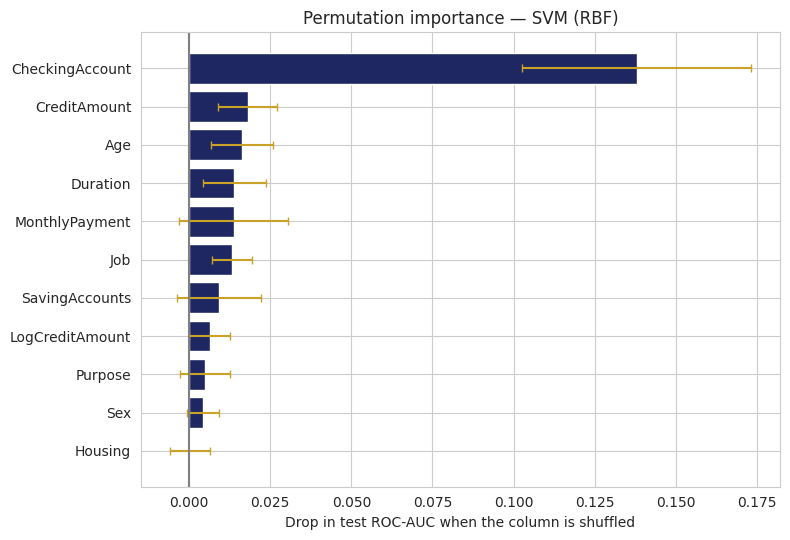

In [15]:
# --- Permutation importance on the ORIGINAL columns (so one-hot pieces are grouped back together) ---
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",  # نخلط كل عمود ونقيس كم بينزل الـ AUC
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)  # 30 مرة خلط لكل عمود عشان النتيجة تكون مستقرة

imp = (pd.DataFrame({"Feature": X_test.columns, "Importance": perm.importances_mean, "Std": perm.importances_std})  # جدول الأهمية بالأعمدة الأصلية
         .sort_values("Importance", ascending=True))  # ترتيب تصاعدي للرسم

plt.figure(figsize=(8, 5.5))  # حجم الرسمة
plt.barh(imp["Feature"], imp["Importance"], xerr=imp["Std"], color=NAVY, ecolor=GOLD, capsize=3)  # الأهمية مع الخطأ المعياري
plt.axvline(0, color="grey")  # خط الصفر
plt.xlabel("Drop in test ROC-AUC when the column is shuffled")  # تسمية المحور الأفقي
plt.title(f"Permutation importance — {best_name}")  # عنوان الرسمة
plt.tight_layout()  # ترتيب المسافات
plt.show()  # عرض الرسمة